# Recipe: An eccentric ring: pericentre and apocentre glow

A ring with e = 0.3 seen face-on at 24 and 870 micron. The flux along the ring is integrated in azimuth bins: at 24 micron the pericentre side is brighter (warmer dust), at 870 micron the apocentre side (more dust per unit length).

**Files:** `examples/eccentric_ring.nml`  
**Run time:** about 5 s  
**Manual:** Sect. 16.3 of `docs/manual/dms_manual.pdf`. The same code as a script: `python3 examples/recipes/eccentric_ring.py`.

In [1]:
# Setup: this notebook lives in examples/recipes/ of the repository
import os, sys
if "REPO" not in globals():
    REPO = os.environ.get("DMS_REPO") or os.path.abspath(os.path.join("..", ".."))
sys.path.insert(0, os.path.join(REPO, "python"))      # use the DMS of this repository
os.chdir(REPO)                                        # input files and cache/ are relative to the root
import dms
import numpy as np
import matplotlib.pyplot as plt
print("DMS", dms.__version__)

DMS 2.2.1


   24 micron: pericentre / apocentre flux per 15 deg = 2.36
  870 micron: pericentre / apocentre flux per 15 deg = 0.43


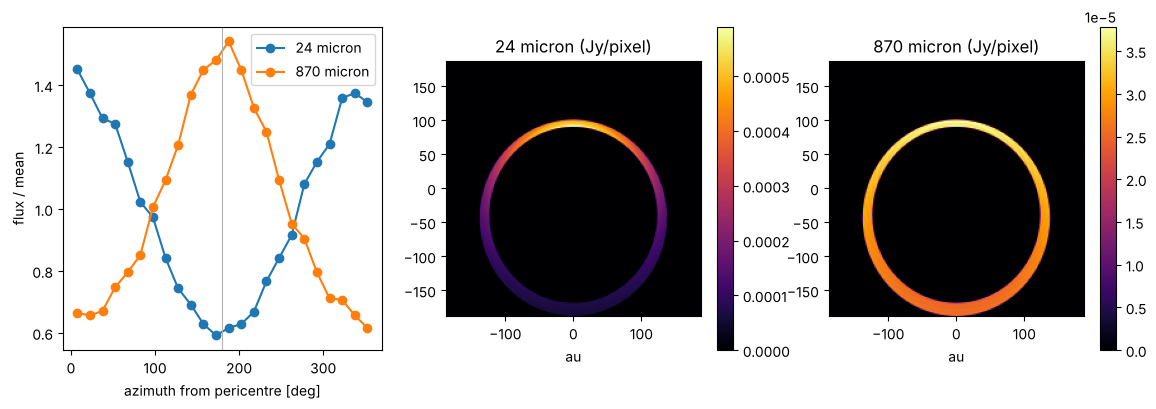

In [2]:
res = dms.Model.from_file("examples/eccentric_ring.nml").run()
img = res.image("thermal")                        # [wavelength, y, x], Jy/pixel
n = img.shape[-1]
x = (np.arange(n) - (n - 1) / 2) * res.pixel_au   # au; pericentre along +y (omega = 0, PA = 0)
X, Y = np.meshgrid(x, x)
phi = np.degrees(np.arctan2(X, Y)) % 360          # azimuth from the pericentre direction
bins = np.arange(0, 361, 15)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for il, lam in enumerate(res.wavelength):
    flux = np.array([img[il][(phi >= a) & (phi < b)].sum() for a, b in zip(bins[:-1], bins[1:])])
    ax[0].plot(0.5 * (bins[:-1] + bins[1:]), flux / flux.mean(), marker="o", label=f"{lam:g} micron")
    print(f"{lam:5g} micron: pericentre / apocentre flux per 15 deg = {flux[0] / flux[len(flux) // 2]:.2f}")
    p = ax[il + 1].imshow(img[il], origin="lower", cmap="inferno", extent=[x[0], x[-1], x[0], x[-1]])
    ax[il + 1].set_title(f"{lam:g} micron (Jy/pixel)"); ax[il + 1].set_xlabel("au")
    plt.colorbar(p, ax=ax[il + 1])
ax[0].set_xlabel("azimuth from pericentre [deg]"); ax[0].set_ylabel("flux / mean")
ax[0].legend(); ax[0].axvline(180, color="0.7", lw=0.8)
plt.show()

**Result.** At 24 µm the pericentre side is 2.4 times brighter than the apocentre side: its dust is closer to the star and warmer (pericentre glow). At 870 µm the ratio is 0.43: the dust moves slowly near apocentre and piles up there, and the Rayleigh–Jeans emission depends only weakly on the temperature (apocentre glow).